
✅ Benchmark summary saved to: computational_complexity_summary.csv
✅ Architectural patch specifications table saved to: model_architectures_patch_specs.csv

🎯 COMPUTATIONAL LATENCY BENCHMARK WITH P95 AND IQR (CPU Inference)
Architecture         Dataset  Total_Params  Disk_Size_MB  Latency_Mean_ms  Latency_Median_ms  Latency_P95_ms  Throughput_s RealTime_Viable_P95 (<100ms)
      EEGNET             Raw         45570          0.59            15.45              14.80           19.57          64.7                          Yes
      EEGNET Filtered_8_30Hz         19778          0.30            14.33              14.27           15.13          69.8                          Yes
      EEGNET Filtered_8_13Hz         19778          0.30            12.46              12.15           14.46          80.3                          Yes
         CVT             Raw        461570          5.59            27.21              26.76           29.92          36.7                          Yes
         CVT Fi

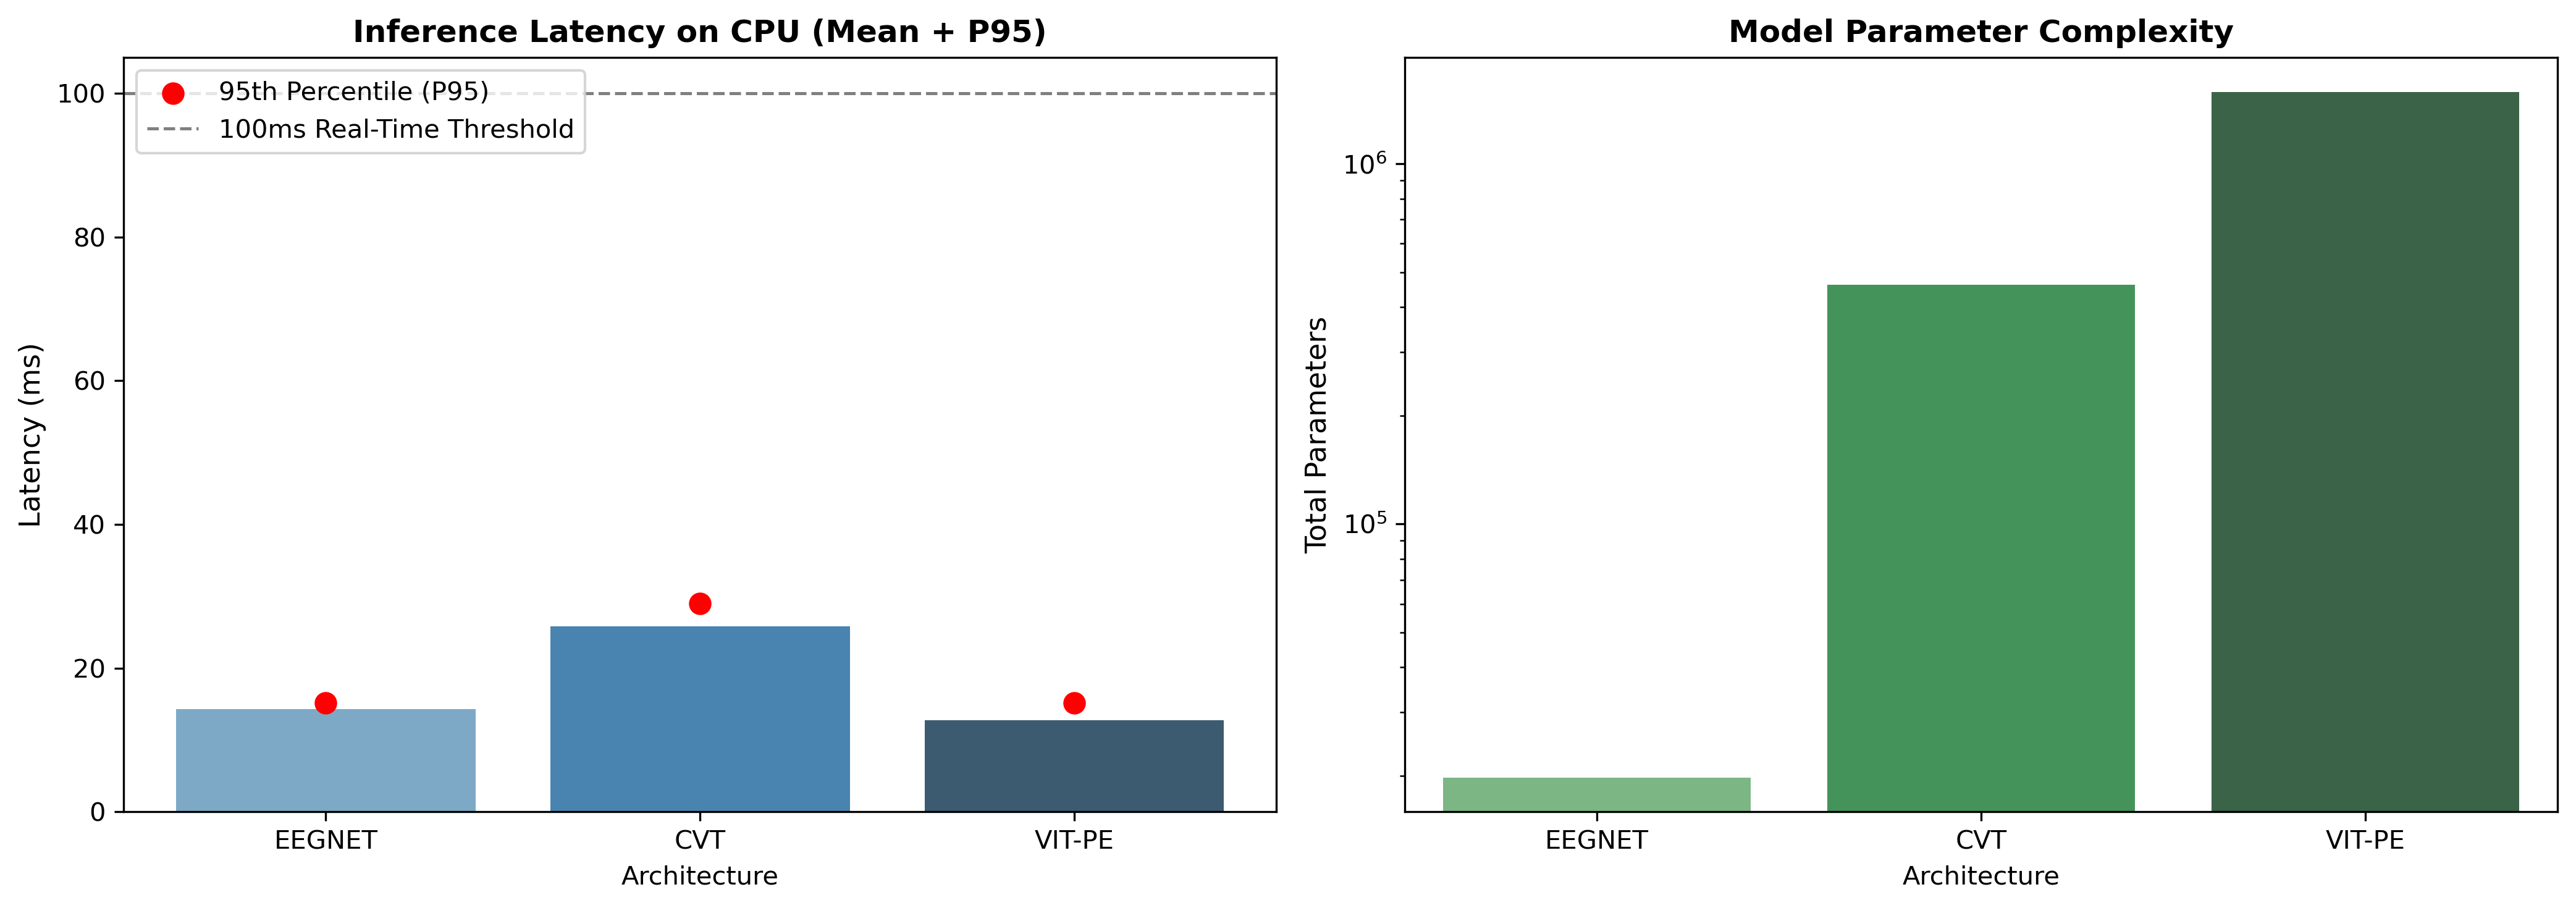

✅ Generated publication figures: computational_complexity_comparison.png & computational_complexity_comparison.pdf


In [2]:
# ==============================================================================
# Computational Complexity & Real-Time Latency Benchmark Pipeline
# Evaluates: Parameters, Disk Size, Latency (Mean, SD, Median, IQR, P95), Throughput
# Includes: Comprehensive Architectural & Patch Specification Table
# ==============================================================================
import os
import gc
import time
import glob
import warnings
from pathlib import Path

# Enforce CPU execution for deterministic inference timing
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Layer, Dense

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------------------
# 1. Project Directory Resolution
# ------------------------------------------------------------------------------
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "Analysis").is_dir() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate project root containing Analysis/ and results/")

PROJECT_ROOT = find_project_root()
ANALYSIS_DIR = PROJECT_ROOT / "Analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Locate Models / Checkpoints directory
POSSIBLE_MODELS_DIRS = [
    PROJECT_ROOT.parent / "MI BCI" / "models",
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "Models",
    PROJECT_ROOT / "checkpoints",
]

CHECKPOINTS_DIR = None
for p in POSSIBLE_MODELS_DIRS:
    if p.is_dir() and any(p.glob("*.h5")):
        CHECKPOINTS_DIR = p
        break

if CHECKPOINTS_DIR is None:
    raise FileNotFoundError("Could not locate trained model checkpoints (*.h5).")

print(f"🚀 Project root: {PROJECT_ROOT}")
print(f"📁 Checkpoints:  {CHECKPOINTS_DIR}")

# ------------------------------------------------------------------------------
# 2. Authentic Custom Transformer Layers (Exact match with ViT-PE.ipynb)
# ------------------------------------------------------------------------------
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super(Patches, self).__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        # Reshape to (batch, num_patches, patch_size, channels)
        patches = tf.reshape(signals, [batch_size, -1, self.patch_size, tf.shape(signals)[-1]])
        return patches

    def get_config(self):
        config = super(Patches, self).get_config()
        config.update({"patch_size": self.patch_size})
        return config


class PatchEncoder(Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super(PatchEncoder, self).__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = Dense(units=projection_dim)

        pos_encoding_matrix = self.get_sinusoidal_position_embedding(num_patches, projection_dim)
        self.position_embedding = tf.Variable(
            pos_encoding_matrix, trainable=False, name="position_embedding"
        )

    def get_sinusoidal_position_embedding(self, sequence_length, embedding_dim):
        angle_rates = 1.0 / (10000 ** (tf.range(0, embedding_dim, 2, dtype=tf.float32) / float(embedding_dim)))
        positions = tf.range(sequence_length, dtype=tf.float32)[:, tf.newaxis]
        angle_rads = positions * angle_rates[tf.newaxis, :]
        sines = tf.math.sin(angle_rads)
        cosines = tf.math.cos(angle_rads)
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        return pos_encoding

    def call(self, patch):
        batch_size = tf.shape(patch)[0]
        patch_height = patch.shape[-2]
        patch_width = patch.shape[-1]
        patch_flattened = tf.reshape(patch, [batch_size, self.num_patches, patch_height * patch_width])
        encoded = self.projection(patch_flattened)
        encoded += self.position_embedding
        return encoded

    def get_config(self):
        config = super(PatchEncoder, self).get_config()
        config.update({"num_patches": self.num_patches, "projection_dim": self.projection_dim})
        return config


class SinusoidalPositionEmbedding(Layer):
    def __init__(self, sequence_length=None, dim=None, **kwargs):
        standard_layer_keys = ['trainable', 'name', 'dtype', 'dynamic']
        base_kwargs = {k: v for k, v in kwargs.items() if k in standard_layer_keys}
        super().__init__(**base_kwargs)
        self.sequence_length = sequence_length
        self.dim = dim
        self.extra_kwargs = kwargs.copy()

    def call(self, x):
        seq_len = tf.shape(x)[1]
        d_model = tf.shape(x)[2] if self.dim is None else self.dim
        pos = tf.cast(tf.range(seq_len)[:, tf.newaxis], tf.float32)
        i = tf.cast(tf.range(d_model)[tf.newaxis, :], tf.float32)
        angle_rates = 1.0 / tf.pow(10000.0, (2.0 * (i // 2)) / tf.cast(d_model, tf.float32))
        angle_rads = pos * angle_rates
        sines = tf.sin(angle_rads[:, 0::2])
        cosines = tf.cos(angle_rads[:, 1::2])
        pos_encoding = tf.concat([sines, cosines], axis=-1)[tf.newaxis, ...]
        return x + tf.cast(pos_encoding, x.dtype)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "dim": self.dim,
            **self.extra_kwargs
        })
        return config


CUSTOM_OBJECTS = {
    "Patches": Patches,
    "PatchEncoder": PatchEncoder,
    "SinusoidalPositionEmbedding": SinusoidalPositionEmbedding,
}

# ------------------------------------------------------------------------------
# 3. Precision Latency Benchmarking (Quartiles & P95)
# ------------------------------------------------------------------------------
def benchmark_inference_profile(model, num_warmup=15, num_repeats=100):
    # Determine the model's expected input shape automatically
    in_shape = model.input_shape
    if in_shape[0] is None:
        test_shape = (1,) + in_shape[1:]
    else:
        test_shape = in_shape
        
    dummy_input = np.random.randn(*test_shape).astype(np.float32)
    
    # Warmup runs on CPU
    with tf.device('/CPU:0'):
        for _ in range(num_warmup):
            _ = model(dummy_input, training=False)
            
        latencies = []
        for _ in range(num_repeats):
            t0 = time.perf_counter()
            _ = model(dummy_input, training=False)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) * 1000.0)  # ms
            
    latencies = np.array(latencies)
    return {
        "mean_latency_ms": float(np.mean(latencies)),
        "std_latency_ms": float(np.std(latencies)),
        "median_latency_ms": float(np.median(latencies)),
        "p25_latency_ms": float(np.percentile(latencies, 25)),
        "p75_latency_ms": float(np.percentile(latencies, 75)),
        "iqr_latency_ms": float(np.percentile(latencies, 75) - np.percentile(latencies, 25)),
        "p95_latency_ms": float(np.percentile(latencies, 95)),
        "throughput_samples_s": float(1000.0 / np.mean(latencies))
    }

# ------------------------------------------------------------------------------
# 4. Run Benchmarks on All Models & Datasets
# ------------------------------------------------------------------------------
ARCHITECTURES = ["eegnet", "cvt", "vit_pe"]
DATASETS = ["Raw", "Filtered_8_30Hz", "Filtered_8_13Hz"]

benchmark_results = []

for arch in ARCHITECTURES:
    for ds in DATASETS:
        # Match checkpoints (favor fold1)
        matches = list(CHECKPOINTS_DIR.glob(f"*{arch}*{ds}*.h5"))
        if not matches:
            matches = list(CHECKPOINTS_DIR.glob(f"*{arch}*fold1*.h5"))
            
        if not matches:
            print(f"⚠️ No checkpoint found for {arch.upper()} on {ds}")
            continue
            
        ckpt_path = matches[0]
        model = tf.keras.models.load_model(ckpt_path, custom_objects=CUSTOM_OBJECTS, compile=False)
        
        total_params = int(model.count_params())
        trainable_params = int(np.sum([tf.size(w).numpy() for w in model.trainable_weights]))
        non_trainable_params = total_params - trainable_params
        disk_size_mb = float(ckpt_path.stat().st_size / (1024 * 1024))
        
        prof = benchmark_inference_profile(model)
        
        benchmark_results.append({
            "Architecture": arch.upper().replace("_", "-"),
            "Dataset": ds,
            "Total_Params": total_params,
            "Trainable_Params": trainable_params,
            "Non_Trainable_Params": non_trainable_params,
            "Disk_Size_MB": round(disk_size_mb, 2),
            "Latency_Mean_ms": round(prof["mean_latency_ms"], 2),
            "Latency_SD_ms": round(prof["std_latency_ms"], 2),
            "Latency_Median_ms": round(prof["median_latency_ms"], 2),
            "Latency_IQR_ms": round(prof["iqr_latency_ms"], 2),
            "Latency_P95_ms": round(prof["p95_latency_ms"], 2),
            "Throughput_s": round(prof["throughput_samples_s"], 1),
            "RealTime_Viable_P95 (<100ms)": "Yes" if prof["p95_latency_ms"] < 100.0 else "No"
        })
        
        del model
        gc.collect()
        tf.keras.backend.clear_session()

bench_df = pd.DataFrame(benchmark_results)
bench_csv_path = ANALYSIS_DIR / "computational_complexity_summary.csv"
bench_df.to_csv(bench_csv_path, index=False)
print(f"\n✅ Benchmark summary saved to: {bench_csv_path.name}")

# ------------------------------------------------------------------------------
# 5. Architecture Specifications & Patch Dimension Table (Reviewer 3)
# ------------------------------------------------------------------------------
arch_specs = [
    {
        "Architecture": "EEGNet",
        "Temporal Filter": "1×64 Conv2D (F1=8)",
        "Spatial Filter": "27×1 DepthwiseConv (D=2, F2=16)",
        "Separable Filter": "1×16 SeparableConv2D",
        "Patch / Token Representation": "Continuous Temporal Convolutions (No Patching)",
        "Sequence / Token Count": "N/A",
        "Attention Heads / Depth": "N/A (Fully CNN)",
    },
    {
        "Architecture": "CvT (Convolutional ViT)",
        "Temporal Filter": "Hierarchical Convolutional Token Embeddings",
        "Spatial / Conv Projection": "Depthwise Sep Conv Projection in Self-Attention",
        "Separable Filter": "Kernel Size (1, 32 / 1, 16)",
        "Patch / Token Representation": "Convolutional Overlapping Patches",
        "Sequence / Token Count": "Multi-stage downsampled (Stage 1-3)",
        "Attention Heads / Depth": "Stage 1: 1H, Stage 2: 3H, Stage 3: 6H",
    },
    {
        "Architecture": "ViT-PE (Pure ViT)",
        "Temporal Filter": "Linear Patch Projection Layer",
        "Spatial Filter": "Channel-wide Patch Flattening",
        "Separable Filter": "None (Dense Linear Projections)",
        "Patch / Token Representation": "Temporal Reshaped Patches (P = 128 / 320)",
        "Sequence / Token Count": "20 or 40 Tokens (2560 timepoints / P)",
        "Attention Heads / Depth": "4 or 8 Attention Heads, 2 to 6 Transformer Blocks",
    }
]

arch_specs_df = pd.DataFrame(arch_specs)
specs_csv_path = ANALYSIS_DIR / "model_architectures_patch_specs.csv"
arch_specs_df.to_csv(specs_csv_path, index=False)
print(f"✅ Architectural patch specifications table saved to: {specs_csv_path.name}")

# ------------------------------------------------------------------------------
# 6. Display Clean Summary Tables
# ------------------------------------------------------------------------------
print("\n" + "="*115)
print("🎯 COMPUTATIONAL LATENCY BENCHMARK WITH P95 AND IQR (CPU Inference)")
print("="*115)
display_cols = [
    "Architecture", "Dataset", "Total_Params", "Disk_Size_MB", 
    "Latency_Mean_ms", "Latency_Median_ms", "Latency_P95_ms", "Throughput_s", "RealTime_Viable_P95 (<100ms)"
]
print(bench_df[display_cols].to_string(index=False))

print("\n" + "="*115)
print("🎯 ARCHITECTURAL & PATCH TOKEN SPECIFICATIONS (Reviewer 3 Response)")
print("="*115)
print(arch_specs_df[["Architecture", "Patch / Token Representation", "Sequence / Token Count", "Attention Heads / Depth"]].to_string(index=False))

# ------------------------------------------------------------------------------
# 7. Publication Figure: Latency (Mean + P95 Error) and Model Parameters
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

arch_order = ["EEGNET", "CVT", "VIT-PE"]
bench_filtered = bench_df[bench_df["Dataset"] == "Filtered_8_30Hz"]

if not bench_filtered.empty:
    sns.barplot(
        data=bench_filtered, x="Architecture", y="Latency_Mean_ms",
        palette="Blues_d", ax=axes[0], order=arch_order
    )
    for idx, arch_name in enumerate(arch_order):
        row = bench_filtered[bench_filtered["Architecture"] == arch_name]
        if not row.empty:
            p95 = row["Latency_P95_ms"].values[0]
            axes[0].scatter(idx, p95, color="red", s=60, zorder=5, label="95th Percentile (P95)" if idx==0 else "")

    axes[0].set_title("Inference Latency on CPU (Mean + P95)", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Latency (ms)", fontsize=11)
    axes[0].axhline(100.0, color="gray", linestyle="--", linewidth=1.2, label="100ms Real-Time Threshold")
    axes[0].legend(loc="upper left")

    sns.barplot(
        data=bench_filtered, x="Architecture", y="Total_Params",
        palette="Greens_d", ax=axes[1], order=arch_order
    )
    axes[1].set_title("Model Parameter Complexity", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Total Parameters", fontsize=11)
    axes[1].set_yscale("log")

plt.tight_layout()
fig_png = ANALYSIS_DIR / "computational_complexity_comparison.png"
fig_pdf = ANALYSIS_DIR / "computational_complexity_comparison.pdf"
plt.savefig(fig_png, dpi=300)
plt.savefig(fig_pdf)
plt.show()
print(f"✅ Generated publication figures: {fig_png.name} & {fig_pdf.name}")